# Rotational Spectra of Hydrogen

The rotational spectrum of hydrogen, a linear molecule, is computed by the phase-space sampling (see also section III A of the paper).

| Redundant space | Potential | Integrator | Physical space |
|---|---|---|---|
| Cartesian (6 DOFs) with 4 constraints (bond and 3 translations) | `ZeroPotential` | `ShakeRattle` | 2D sphere (polar $\theta$ and azimuthal angle $\phi$) |

- **Rigid rotor**: The bond length and the center of mass are fixed by constraints. Since the potential energy is constant for the rigid rotation, `ZeroPotential` is used (see the *Constrained Dynamics* tutorial), and no Hessian evaluation is needed.

- **Initial states**: Coherent states in $(\theta, \phi)$ centered at the reference structure along the x-axis ($\theta = \pi / 2$, $\phi = 0$), with the rotational kinetic energies of 500, 2000 and 5000 $\textrm{cm}^{-1}$ and the widths of 0.2 rad.

- **Sampling**: The initial positions are fixed at the center of the initial states, and the initial momenta perpendicular to the bond are sampled uniformly in the 2D momentum space (the rotational kinetic energy and the direction of the rotation plane are sampled uniformly).

- **Coordinate singularities**: The trajectories pass through the singular points ($\theta = 0, \pi$) depending on the direction of the rotation. The steps where the symplectic condition is not satisfied are excluded.


- **Reference**: The peaks are compared with the analytical rotational levels $E_J = B J(J+1)$.

In [1]:
# import necessary libraries

import sys
import time
from pathlib import Path

sys.path.insert(0, str(Path.cwd().parent))

import numpy as np

from pyscivr.units import FemtoSec, CmInv, HBar
from pyscivr.potentials import ZeroPotential
from pyscivr.coordinates import InternalCoordinates
from pyscivr.integrators import ShakeRattle
from pyscivr.variations import make_vari_propagator, propagate_variation, make_jacobi_func, to_internal
from pyscivr.basis import get_overlap
from pyscivr.scivr import get_lagrangian, get_action, get_prefactor, get_ta_spectrum_fft

## System and coordinates

The system and the coordinates are the same as in the *Constrained Dynamics* tutorial:

`COORD_CONST` defines the constraints (bond length and center of mass), and `COORD_ALL` defines the full set of coordinates, where the polar and azimuthal angles are active.

The Jacobian functions between the redundant and physical spaces are made once and reused for all trajectories.

## Sampling of initial conditions

`initial_momenta` gives the momenta of rigid rotation with the rotational kinetic energy `K_rot`
in the plane tilted by `tilt` from the xy-plane, as in the *Constrained Dynamics* tutorial.

`sample_momenta` samples `K_rot` and `tilt` uniformly, which corresponds to the uniform sampling
of the momenta perpendicular to the bond in the 2D momentum space.
The vibrational kinetic energy `K_vib` is set to zero for the pure rotation.

## Calculation of spectra

`run` computes the spectra for all the initial states by the following steps for each trajectory:

1. Propagate the trajectory by `ShakeRattle`.
2. Propagate the variation and compute the monodromy matrix in the physical space.
   The Hessian is zero for `ZeroPotential`.
3. Exclude the steps where the symplectic condition is not satisfied.
4. Compute the action, the prefactor and the overlap with each initial state, and the spectrum
   by the FFT.

The spectra are averaged over the trajectories and saved for each initial state.
Note that each trajectory is used for all the initial states, so that the cost of the dynamics
and the monodromy matrix is shared.

In [ ]:
# Constants
MASS = np.array([1.008, 1.008]) # mass of hydrogen atoms [amu (atomic mass unit)]
R_E = 0.74160392 # equilibrium bond length [Angs]
POSI_REF = np.array([[-R_E / 2, 0.0, 0.0], [R_E / 2, 0.0, 0.0]])
CALC = ZeroPotential()
ENER_REF = CALC.energy(POSI_REF)

# Coordinate for constraints
COORD_CONST = InternalCoordinates(POSI_REF, MASS)
COORD_CONST.add_bond(0, 1)
COORD_CONST.add_translation()
COORD_CONST.build()

# Coordinate for all DOFs
COORD_ALL = InternalCoordinates(POSI_REF, MASS)
COORD_ALL.add_translation()
COORD_ALL.add_polar(0, 1)
COORD_ALL.add_azimuthal(0, 1)
COORD_ALL.add_bond(0, 1)
COORD_ALL.build()

ACTIVE_IDX = np.array([COORD_ALL.find_coordinate(kind, (0, 1))[0] for kind in ("polar", "azimuthal")])
TOPOLOGIES = [COORD_ALL.topology[i] for i in ACTIVE_IDX]

JACOBI_FUNC, JACOBI_REV_FUNC, INTERNAL_FUNC, MONODROMY_FUNC = make_jacobi_func(COORD_ALL, ACTIVE_IDX)


def initial_momenta(K_rot, K_vib, tilt, sign=1):

    p_rot = np.sqrt(K_rot * CmInv * MASS[0])
    p_vib = np.sqrt(K_vib * CmInv * MASS[0]) * sign
    p_rot_y = p_rot * np.cos(tilt)
    p_rot_z = p_rot * np.sin(tilt)
    return np.array([[-p_vib, -p_rot_y, -p_rot_z], [p_vib, p_rot_y, p_rot_z]])


def sample_momenta(n_sample, K_rot_range, K_vib_range, seed=10202):

    rng = np.random.default_rng(seed)
    K_rot = rng.uniform(*K_rot_range, size=n_sample)
    K_vib = rng.uniform(*K_vib_range, size=n_sample)
    sign = rng.choice([-1, 1], size=n_sample)
    tilt = rng.uniform(0.0, 2.0 * np.pi, size=n_sample)
    return [initial_momenta(K_rot[i], K_vib[i], tilt[i], sign[i]) for i in range(n_sample)], K_rot, K_vib


def run(posi_sample_list, mome_sample_list, K_rot_list, K_vib_list,
        posi_ref_list, mome_ref_list, gamma_ref_list, fpath_list,
        dt, n_step, n_fft, symp_err_tol=1e-4):

    # Judge function to check if the point is singular or not
    judge_func= lambda symp_err : np.isfinite(symp_err) & (symp_err < symp_err_tol)

    # Reference positions and momenta in the internal coordinates
    posi_ref_int, mome_ref_int = zip(*[INTERNAL_FUNC(p, q) for p, q in zip(posi_ref_list, mome_ref_list)])

    n_sample = len(posi_sample_list)
    n_ref = len(posi_ref_list)
    spectra = [0.0] * n_ref
    vari_propagator = make_vari_propagator(COORD_CONST, dt)

    t_start = time.perf_counter()
    for i in range(n_sample):
        # Get trajectory
        dyn = ShakeRattle(CALC, posi_sample_list[i], mome_sample_list[i], MASS, dt, COORD_CONST)
        traj = dyn.run(n_step)
        traj_posi, traj_mome = traj["posi"], traj["mome"]

        # get variation
        hess = CALC.hessian(traj_posi)
        J_rev_init = JACOBI_REV_FUNC(traj_posi[0], traj_mome[0])

        vari = propagate_variation(vari_propagator, traj_posi, traj_mome, traj["lam"], traj["mu"], hess, vari_init=J_rev_init)
        posi_int, mome_int, mono_int, symplectic_error = to_internal(MONODROMY_FUNC, traj_posi, traj_mome, vari)

        # points with large symplectic error are treated as singularities
        valid = judge_func(symplectic_error)

        ener_grid = 2.0 * np.pi * HBar * np.arange(n_fft) / (dt * n_fft)
        lag = get_lagrangian(traj["total_energy"], traj["potential_energy"], ener_ref=ENER_REF)
        action = get_action(lag, dt)

        for j in range(n_ref):
            posi_center, mome_center = posi_ref_int[j], mome_ref_int[j]
            gamma = gamma_ref_list[j]
            prefactor = get_prefactor(mono_int, gamma, valid=valid)
            overlap = get_overlap(TOPOLOGIES, posi_center, mome_center, posi_int, mome_int, gamma)
            _, spec = get_ta_spectrum_fft(prefactor, overlap, action, dt, n_fft, valid=valid)
            spectra[j] += spec

        if i % 10 == 0:
            print(f"{i+1:6d} / {n_sample}, K_rot = {K_rot_list[i]:.1f}, K_vib = {K_vib_list[i]:.1f}, "
                f"max symp error = {np.max(np.abs(symplectic_error)):.3e}, ({time.perf_counter() - t_start:.1f} sec)", flush=True)

    for j in range(n_ref):
        spectra[j] /= n_sample

    for j in range(n_ref):
        np.savez(fpath_list[j], ener_grid=ener_grid, spectrum=spectra[j])

Build complete: 4 coordinates
Build complete: 6 coordinates


## Execute calculation

The total propagation time is 500 fs.

In [3]:
if __name__ == "__main__":
    # set parameters
    n_sample = 2000
    dt = 0.1 * FemtoSec
    n_step = 5000
    n_fft = 2**19

    # set reference state
    K_rot_ref_list = [500.0, 2000.0, 5000.0]

    mome_ref_list = [initial_momenta(k_rot, 0.0, np.pi / 4) for k_rot in K_rot_ref_list]
    posi_ref_list = [POSI_REF] * len(K_rot_ref_list)

    gamma_ref = [1.0 / (2 * 0.2 ** 2),  # sqrt(1 / 2 gamma) = 0.2 rad
                 1.0 / (2 * 0.2 ** 2)]
    gamma_ref_list = [gamma_ref] * len(K_rot_ref_list)
    fpath_list = [f"hydrogen_pure_rot_{k_rot:.0f}_n_{n_sample}_spectra.npz" for k_rot in K_rot_ref_list]

    posi_ref_list = np.asarray(posi_ref_list)
    mome_ref_list = np.asarray(mome_ref_list)
    gamma_ref_list = np.asarray(gamma_ref_list)

    K_rot_range = (10.0, 10000.0)
    K_vib_range = (0.0, 0.0)  # No vibrational kinetic energy for pure rotational motion
    mome_sample_list, K_rot_list, K_vib_list = sample_momenta(n_sample, K_rot_range, K_vib_range)
    posi_sample_list = np.asarray([POSI_REF] * n_sample)

    run(posi_sample_list, mome_sample_list, K_rot_list, K_vib_list,
        posi_ref_list, mome_ref_list, gamma_ref_list, fpath_list,
        dt, n_step, n_fft)

     1 / 2000, K_rot = 2788.2, K_vib = 0.0, max symp error = 2.680e-09, (1.2 sec)
    11 / 2000, K_rot = 4946.9, K_vib = 0.0, max symp error = 3.705e-10, (5.6 sec)
    21 / 2000, K_rot = 9808.5, K_vib = 0.0, max symp error = 2.921e-10, (10.0 sec)
    31 / 2000, K_rot = 8930.5, K_vib = 0.0, max symp error = 1.116e-09, (14.7 sec)
    41 / 2000, K_rot = 1592.5, K_vib = 0.0, max symp error = 7.402e-10, (19.2 sec)
    51 / 2000, K_rot = 7396.6, K_vib = 0.0, max symp error = 1.458e-10, (23.8 sec)
    61 / 2000, K_rot = 2192.0, K_vib = 0.0, max symp error = 1.056e-09, (28.5 sec)
    71 / 2000, K_rot = 6597.3, K_vib = 0.0, max symp error = 5.435e-10, (33.0 sec)
    81 / 2000, K_rot = 2769.8, K_vib = 0.0, max symp error = 1.855e-09, (37.6 sec)
    91 / 2000, K_rot = 2161.3, K_vib = 0.0, max symp error = 1.721e-09, (42.1 sec)
   101 / 2000, K_rot = 3024.0, K_vib = 0.0, max symp error = 1.338e-09, (46.7 sec)
   111 / 2000, K_rot = 4798.8, K_vib = 0.0, max symp error = 8.624e-10, (51.1 sec)
   121

## Plot results

The reference rotational energies can be calculated analytically using the formula $E_J = B_e J(J+1)$, where $B_e = \frac{\hbar^2}{2I}$ is the rotational constant and $J$ is the rotational quantum number.

The moment of inertia $I$ for H2 can be calculated as $I = \frac{m_H}{2}r_e^2$.

Rotational constant B = 60.817 cm^-1
Analytical rotational energies (cm^-1): [   0.   121.6  364.9  729.8 1216.3 1824.5 2554.3 3405.7 4378.8 5473.5
 6689.8 8027.8 9487.4]
Peaks (cm^-1) for K = 500: [ 111.3  370.3  730.4 1214.5 1826.6 2553.8 3403.8 4377.9]
Peaks (cm^-1) for K = 2000: [ 369.   730.4 1213.3 1825.3 2553.2 3403.2 4376.6 5475.3 6686.1]
Peaks (cm^-1) for K = 5000: [1212.  1824.7 2552.5 3403.2 4375.9 5474.7 6685.4 8028.5 9494.4]


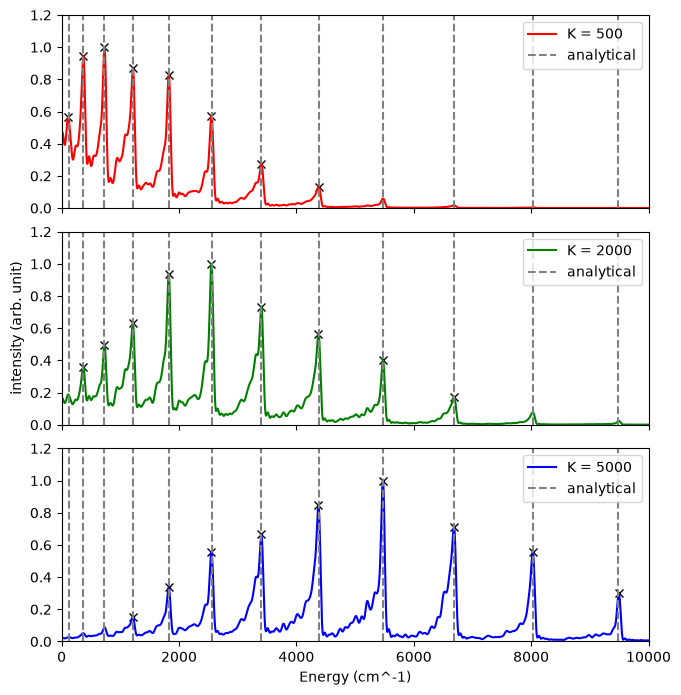

In [28]:
if __name__ == "__main__":
    import matplotlib.pyplot as plt
    from scipy.signal import find_peaks

    # moment of inertia of H2
    I = MASS[0] * R_E**2 / 2.0
    # rotational constant
    B = HBar**2 / (2.0 * I) / CmInv
    analytical_energies = np.array([B * J * (J + 1) for J in range(20) if B * J * (J + 1) <= 10000])
    print(f"Rotational constant B = {B:.3f} cm^-1")
    print(f"Analytical rotational energies (cm^-1): {np.round(analytical_energies, 1)}")

    fig, ax = plt.subplots(3, 1, figsize=(7, 7), sharex=True)
    colors = ["red", "green", "blue"]    

    for i, fpath in enumerate(fpath_list):
        data = np.load(fpath)
        ener_grid = data["ener_grid"] / CmInv
        spectrum = data["spectrum"]
        spectrum /= np.max(spectrum)
        peaks, _ = find_peaks(spectrum, height=0.1, prominence=0.1)
        peaks = peaks[ener_grid[peaks] <= 10000]

        print(f"Peaks (cm^-1) for K = {K_rot_ref_list[i]:.0f}: {np.round(ener_grid[peaks], 1)}")
        ax[i].plot(ener_grid[peaks], spectrum[peaks], "x", color="black")

        ax[i].plot(ener_grid, spectrum, label=f"K = {K_rot_ref_list[i]:.0f}", color=colors[i])
        ax[i].set_xlim(0, 10000)
        ax[i].set_ylim(0, 1.2)
        ax[i].vlines(analytical_energies, 0.0, 1.2, color="gray", linestyle="--", label="analytical")
        ax[i].legend()

    ax[-1].set_xlabel("Energy (cm^-1)")
    ax[1].set_ylabel("intensity (arb. unit)")
    ax[-1].set_xlim(0, 10000)
    plt.tight_layout()    
    plt.show()

The computed peak positions for $K = 2000$ $\textrm{cm}^{-1}$ are compared with the analytical eigenenergies $E_J = B_e J(J+1)$ with $B_e = 60.817$ $\textrm{cm}^{-1}$ (all in $\textrm{cm}^{-1}$).

| $J$ | Computed | $B_e J(J+1)$ | Deviation |
|---|---|---|---|
| 2 | 369.0 | 364.9 | +4.1 |
| 3 | 730.4 | 729.8 | +0.6 |
| 4 | 1213.3 | 1216.3 | −3.0 |
| 5 | 1825.3 | 1824.5 | +0.8 |
| 6 | 2553.2 | 2554.3 | −1.1 |
| 7 | 3403.2 | 3405.7 | −2.5 |
| 8 | 4376.6 | 4378.8 | −2.2 |
| 9 | 5475.3 | 5473.5 | +1.8 |
| 10 | 6686.1 | 6689.8 | −3.7 |

- **Quantitative agreement**: The computed peaks agree with the analytical eigenenergies with an RMSE of about 2.5 $\textrm{cm}^{-1}$, without systematic dependence on $J$. The same peak positions are obtained for all the initial states, up to $J = 12$ (about 9500 $\textrm{cm}^{-1}$) for $K$ = 5000 $\textrm{cm}^{-1}$.

- **Line shape**: Each peak has an asymmetric line shape with a sharp edge at the eigenenergy and a tail on the low-energy side, which originates from the time-averaging expression (see Appendix K of the paper).

- **Dependence on the initial state**: The intensity distribution follows the rotational kinetic energy of the initial state: the strongest peaks appear around 730, 2550 and 5470 $\textrm{cm}^{-1}$ for the initial states with $K$ = 500, 2000 and 5000 $\textrm{cm}^{-1}$, respectively.